# Task 1 & Task 2: Data Understanding, Preprocessing, and Conference Popularity Analysis

Notebook ini mencakup:
1. **Task 1 — Data Understanding & Preprocessing**: eksplorasi struktur dataset DBLP (2015–2025), ringkasan tahapan preprocessing (`src/preprocessing.py`), serta statistik dataset bersih.
2. **Task 2 — Conference Popularity Analysis**: identifikasi Top 10 konferensi berdasarkan jumlah publikasi dan jumlah author unik, tren tahunan (2015–2025), serta perbandingan kedua ranking tersebut.

In [1]:
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

os.makedirs("../outputs/figures", exist_ok=True)
os.makedirs("../tables", exist_ok=True)


## 1. Task 1 — Data Understanding & Preprocessing

Dataset berasal dari DBLP XML Dump (`https://dblp.org/xml/` / mirror `https://dblp.uni-trier.de/xml/`) yang diekstrak untuk entri `<inproceedings>` periode **2015–2025** melalui `src/parser.py`, lalu dibersihkan oleh `src/preprocessing.py`.

In [2]:
with open("../data/raw/metadata.json", "r", encoding="utf-8") as f:
    raw_meta = json.load(f)
with open("../data/processed/preprocessing_summary.json", "r", encoding="utf-8") as f:
    prep_summary = json.load(f)

print("Download metadata (UTC):", raw_meta.get("downloaded_at_utc"))
for fname, info in raw_meta.get("files", {}).items():
    print(f" - {fname}: {info['size_bytes']:,} bytes (sha256: {info['sha256'][:16]}...)")

df_raw = pd.read_parquet("../data/processed/dblp_2015_2025_raw.parquet")
df_clean = pd.read_parquet("../data/processed/dblp_2015_2025_clean.parquet")

print(f"\nRaw shape  : {df_raw.shape}")
print(f"Clean shape: {df_clean.shape}")
print("\nColumns & dtypes (clean):")
print(df_clean.dtypes)
df_clean.head(5)


Download metadata (UTC): 2026-11-19T03:06:47.202393+00:00
 - dblp.dtd: 13,134 bytes (sha256: 03ec35cb34a42275...)
 - dblp.xml.gz: 1,121,975,282 bytes (sha256: 812fd7d6860295a9...)



Raw shape  : (2004202, 5)
Clean shape: (2000757, 5)

Columns & dtypes (clean):
key           str
title         str
authors    object
year        int32
venue         str
dtype: object


,key,title,authors,year,venue
0,books/sp/15/KimLLRJPK15,Performance Analysis of FFNN-Based Language Mo...,"[Kwang-Ho Kim, Donghyun Lee 0001, Minkyu Lim, ...",2015,IWSDS
1,books/sp/15/ManuvinakurikeD15,Pair Me Up: A Web Framework for Crowd-Sourced ...,"[Ramesh R. Manuvinakurike, David DeVault]",2015,IWSDS
2,books/sp/15/YoshinoK15,News Navigation System Based on Proactive Dial...,"[Koichiro Yoshino, Tatsuya Kawahara]",2015,IWSDS
3,books/sp/15/KwonLRHCKJOLKCPL15,GenieTutor: A Computer-Assisted Second-Languag...,"[Oh-Woog Kwon, Ki-Young Lee, Yoon-Hyung Roh, J...",2015,IWSDS
4,books/sp/15/HanKL15,Micro-Counseling Dialog System Based on Semant...,"[Sangdo Han, Yonghee Kim, Gary Geunbae Lee]",2015,IWSDS


### 1.1 Distribusi Jenis Publikasi pada Raw DBLP XML (Task 1.1)

DBLP menyimpan berbagai jenis publikasi ilmiah (artikel jurnal, makalah konferensi/workshop, prosiding, buku, tesis, dll.). Sesuai spesifikasi project, fokus analisis adalah entri bertipe `<inproceedings>` (publikasi konferensi & workshop) pada periode **2015–2025**. Tabel berikut menyajikan distribusi seluruh tipe entri pada dump XML DBLP mentah.


Total seluruh record pada DBLP XML dump: 13,127,979


,publication_type,records,share_pct
0,article,4527388,34.49
1,www,4247510,32.35
2,inproceedings,4004309,30.50
3,phdthesis,158395,1.21
4,incollection,71264,0.54
5,proceedings,65903,0.50
6,data,31529,0.24
7,book,21654,0.16
8,mastersthesis,27,0.00


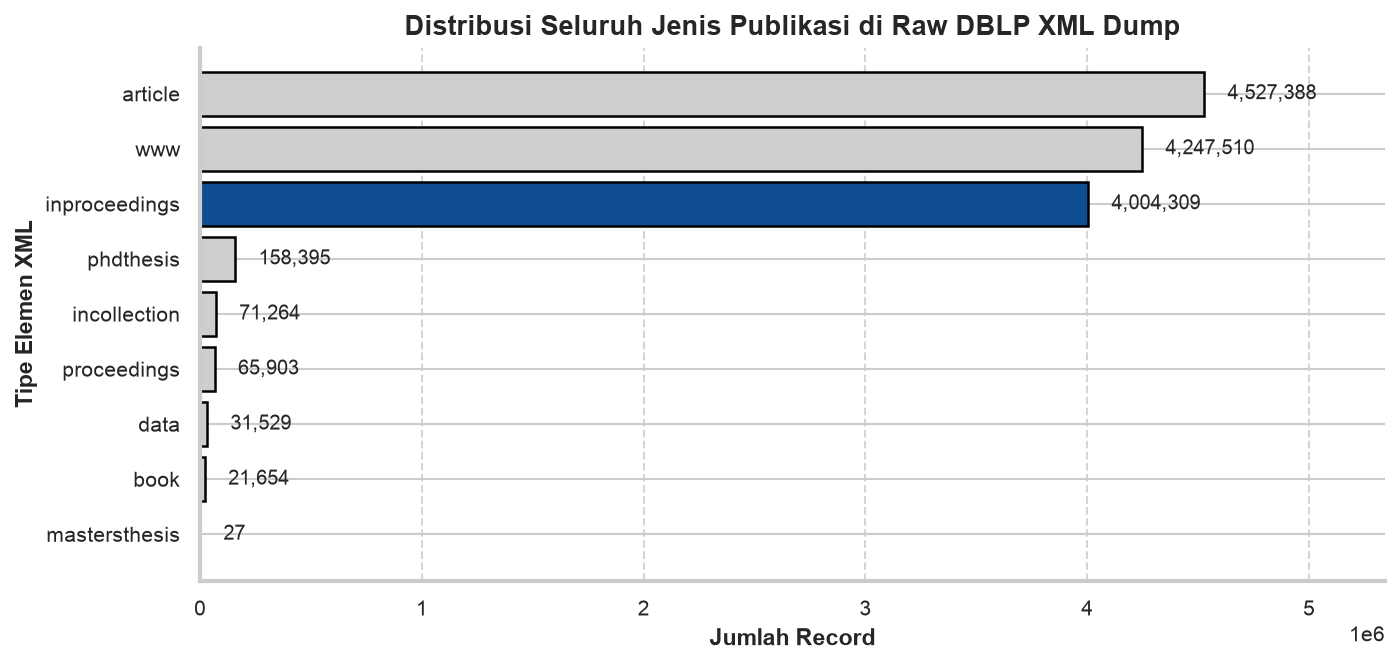

In [3]:
import sys
sys.path.insert(0, "..")
from src.plotting import PALETTE, apply_publication_style, clean_axes, save_figure

apply_publication_style(base_font_size=11)

with open("../data/processed/xml_publication_types.json", "r", encoding="utf-8") as f:
    xml_types = json.load(f)

pub_types_df = pd.DataFrame([
    {"publication_type": k, "records": v, "share_pct": round(v / xml_types["total_records"] * 100, 2)}
    for k, v in xml_types["by_type"].items()
])
pub_types_df.to_csv("../tables/xml_publication_types.csv", index=False)
print(f"Total seluruh record pada DBLP XML dump: {xml_types['total_records']:,}")
display(pub_types_df)

fig, ax = plt.subplots(figsize=(9.5, 4.6))
colors = [PALETTE["blue_main"] if t == "inproceedings" else PALETTE["neutral"] for t in pub_types_df["publication_type"]]
bars = ax.barh(pub_types_df["publication_type"][::-1], pub_types_df["records"][::-1], color=colors[::-1], edgecolor="black", linewidth=1.2)
for bar in bars:
    w = bar.get_width()
    ax.text(w + xml_types["total_records"] * 0.008, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", va="center", fontsize=9.5)
ax.set_title("Distribusi Seluruh Jenis Publikasi di Raw DBLP XML Dump")
ax.set_xlabel("Jumlah Record")
ax.set_ylabel("Tipe Elemen XML")
ax.set_xlim(0, pub_types_df["records"].max() * 1.18)
clean_axes(ax, grid_axis="x")
save_figure(fig, "../outputs/figures/01_xml_publication_types")
plt.show()


### 1.1 Distribusi Jenis Publikasi pada Raw DBLP XML (Task 1.1)

DBLP menyimpan berbagai jenis publikasi ilmiah (artikel jurnal, makalah konferensi/workshop, prosiding, buku, tesis, dll.). Sesuai spesifikasi project, fokus analisis adalah entri bertipe `<inproceedings>` (publikasi konferensi & workshop) pada periode **2015–2025**. Tabel berikut menyajikan distribusi seluruh tipe entri pada dump XML DBLP mentah.


### 1.3 Penjelasan Tahapan Preprocessing dan Alasan Pemilihan Metode (Task 1.3)

| No | Tahap Preprocessing | Metode yang Diterapkan | Alasan Pemilihan Metode |
|---|---|---|---|
| 1 | **Seleksi Tipe Publikasi** | Streaming XML (`lxml.etree.iterparse`) khusus tag `<inproceedings>` dengan resolusi entitas DTD | File XML mentah berukuran >4 GB (terkompresi ~1.07 GiB). Streaming `iterparse` menjaga konsumsi memori tetap rendah dan memastikan hanya makalah konferensi/workshop yang diekstrak. |
| 2 | **Konsistensi Tahun Publikasi** | Konversi numerik ketat (`int32`) dan filter rentang `2015–2025` | Memastikan seluruh data berada dalam periode pengamatan 11 tahun yang diminta serta menghindari anomali tipe data/tahun di luar rentang. |
| 3 | **Penanganan Missing Values** | Penghapusan baris dengan `key`, `title`, `venue` kosong, atau daftar `authors` kosong | Atribut `authors` dan `venue` adalah komponen wajib untuk membentuk transaksi `(author -> {venues})`. Record tanpa penulis atau tanpa venue tidak dapat diimputasi secara valid. |
| 4 | **Normalisasi Nama Author** | Unicode NFC + kolaps spasi berlebih + deduplikasi author per paper, **mempertahankan** suffix disambiguasi DBLP (mis. `0001`) | Unicode NFC menyatukan karakter diakritik yang berbeda representasi byte. Suffix numerik DBLP sengaja dipertahankan karena berfungsi membedakan peneliti berbeda yang memiliki nama homonim. |
| 5 | **Normalisasi Nama Conference/Venue** | Penyeragaman spasi di sekitar `@`, penyatuan `(Workshops)` → `Workshops`, pemetaan alias historis (`NIPS` → `NeurIPS`), dan *canonical casing* berbasis frekuensi terbanyak | Menggabungkan varian penulisan konferensi yang sama (seperti pergantian nama resmi `NIPS` menjadi `NeurIPS` pada 2018 serta inkonsistensi huruf besar/kecil) agar tidak memecah support venue. |
| 6 | **Deduplikasi Data** | Dua tahap: (a) deduplikasi berdasarkan DBLP `key`, dan (b) deduplikasi konten berdasarkan `(normalized_title, year, venue)` | Menghilangkan entri ganda akibat duplikasi indexing lintas prosiding atau perbedaan tanda baca pada judul di tahun dan venue yang sama. |


Total seluruh record pada DBLP XML dump: 13,127,979


,publication_type,records,share_pct
0,article,4527388,34.49
1,www,4247510,32.35
2,inproceedings,4004309,30.50
3,phdthesis,158395,1.21
4,incollection,71264,0.54
5,proceedings,65903,0.50
6,data,31529,0.24
7,book,21654,0.16
8,mastersthesis,27,0.00


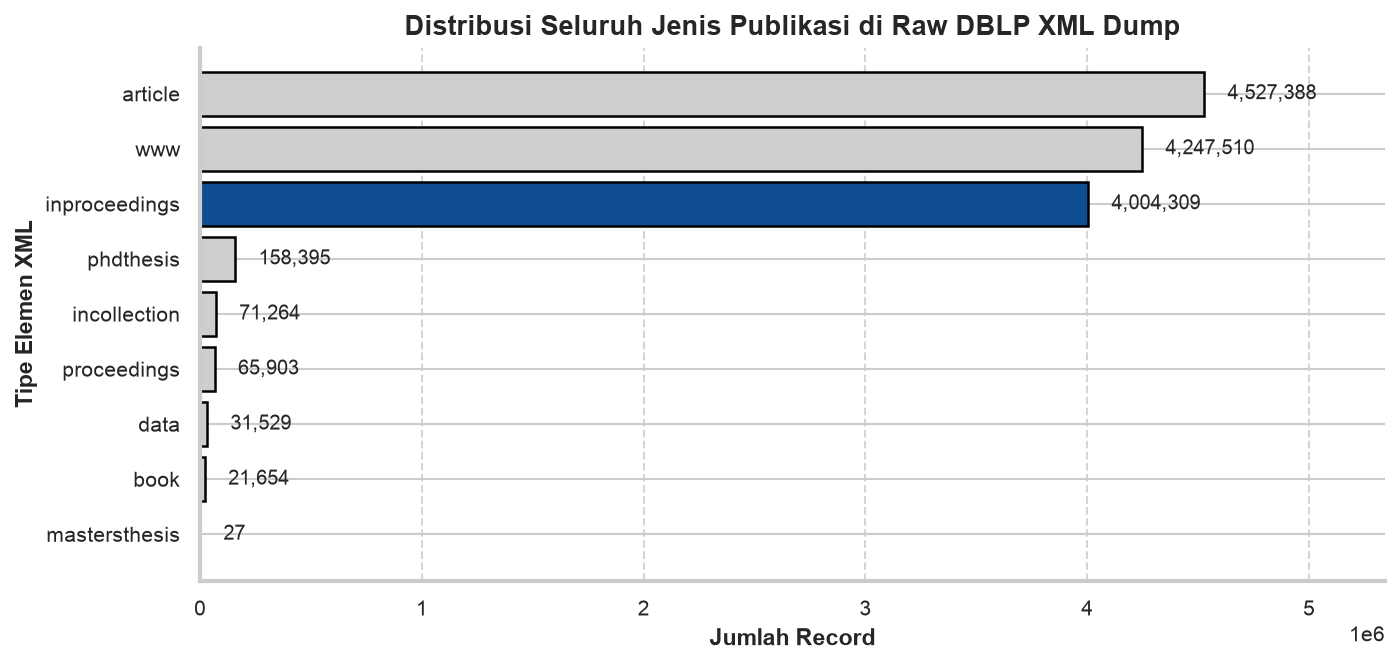

In [4]:
import sys
sys.path.insert(0, "..")
from src.plotting import PALETTE, apply_publication_style, clean_axes, save_figure

apply_publication_style(base_font_size=11)

with open("../data/processed/xml_publication_types.json", "r", encoding="utf-8") as f:
    xml_types = json.load(f)

pub_types_df = pd.DataFrame([
    {"publication_type": k, "records": v, "share_pct": round(v / xml_types["total_records"] * 100, 2)}
    for k, v in xml_types["by_type"].items()
])
pub_types_df.to_csv("../tables/xml_publication_types.csv", index=False)
print(f"Total seluruh record pada DBLP XML dump: {xml_types['total_records']:,}")
display(pub_types_df)

fig, ax = plt.subplots(figsize=(9.5, 4.6))
colors = [PALETTE["blue_main"] if t == "inproceedings" else PALETTE["neutral"] for t in pub_types_df["publication_type"]]
bars = ax.barh(pub_types_df["publication_type"][::-1], pub_types_df["records"][::-1], color=colors[::-1], edgecolor="black", linewidth=1.2)
for bar in bars:
    w = bar.get_width()
    ax.text(w + xml_types["total_records"] * 0.008, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", va="center", fontsize=9.5)
ax.set_title("Distribusi Seluruh Jenis Publikasi di Raw DBLP XML Dump")
ax.set_xlabel("Jumlah Record")
ax.set_ylabel("Tipe Elemen XML")
ax.set_xlim(0, pub_types_df["records"].max() * 1.18)
clean_axes(ax, grid_axis="x")
save_figure(fig, "../outputs/figures/01_xml_publication_types")
plt.show()


In [5]:
# Ringkasan DBLP key prefix pada dataset bersih & ringkasan preprocessing
key_prefixes = df_clean["key"].str.split("/").str[0].value_counts()
print("Distribusi prefix key pada data bersih:")
display(key_prefixes.to_frame("count"))

prep_table = pd.DataFrame([
    {"Tahap": "Raw records (inproceedings 2015-2025)", "Jumlah": prep_summary["raw_records"]},
    {"Tahap": "Dropped: invalid year", "Jumlah": -prep_summary["dropped_invalid_year"]},
    {"Tahap": "Dropped: missing key/title", "Jumlah": -prep_summary["dropped_missing_key_or_title"]},
    {"Tahap": "Dropped: missing/empty venue", "Jumlah": -prep_summary["dropped_missing_venue"]},
    {"Tahap": "Dropped: empty authors", "Jumlah": -prep_summary["dropped_empty_authors"]},
    {"Tahap": "Dropped: duplicate key", "Jumlah": -prep_summary["dropped_duplicate_key"]},
    {"Tahap": "Dropped: duplicate (title_norm, year, venue)", "Jumlah": -prep_summary["dropped_duplicate_title_year_venue"]},
    {"Tahap": "Cleaned records", "Jumlah": prep_summary["cleaned_records"]},
])
prep_table.to_csv("../tables/preprocessing_summary.csv", index=False)
display(prep_table)

print(f"Total publikasi bersih : {prep_summary['cleaned_records']:,}")
print(f"Total author unik      : {prep_summary['unique_authors']:,}")
print(f"Total venue unik       : {prep_summary['unique_venues']:,}")


Distribusi prefix key pada data bersih:


,count
key,
conf,1997597
journals,3120
books,40


,Tahap,Jumlah
0,Raw records (inproceedings 2015-2025),2004202
1,Dropped: invalid year,0
2,Dropped: missing key/title,0
3,Dropped: missing/empty venue,-190
4,Dropped: empty authors,-2255
5,Dropped: duplicate key,0
6,"Dropped: duplicate (title_norm, year, venue)",-1000
7,Cleaned records,2000757


Total publikasi bersih : 2,000,757
Total author unik      : 1,822,489
Total venue unik       : 8,780


### 1.3 Penjelasan Tahapan Preprocessing dan Alasan Pemilihan Metode (Task 1.3)

| No | Tahap Preprocessing | Metode yang Diterapkan | Alasan Pemilihan Metode |
|---|---|---|---|
| 1 | **Seleksi Tipe Publikasi** | Streaming XML (`lxml.etree.iterparse`) khusus tag `<inproceedings>` dengan resolusi entitas DTD | File XML mentah berukuran >4 GB (terkompresi ~1.07 GiB). Streaming `iterparse` menjaga konsumsi memori tetap rendah dan memastikan hanya makalah konferensi/workshop yang diekstrak. |
| 2 | **Konsistensi Tahun Publikasi** | Konversi numerik ketat (`int32`) dan filter rentang `2015–2025` | Memastikan seluruh data berada dalam periode pengamatan 11 tahun yang diminta serta menghindari anomali tipe data/tahun di luar rentang. |
| 3 | **Penanganan Missing Values** | Penghapusan baris dengan `key`, `title`, `venue` kosong, atau daftar `authors` kosong | Atribut `authors` dan `venue` adalah komponen wajib untuk membentuk transaksi `(author -> {venues})`. Record tanpa penulis atau tanpa venue tidak dapat diimputasi secara valid. |
| 4 | **Normalisasi Nama Author** | Unicode NFC + kolaps spasi berlebih + deduplikasi author per paper, **mempertahankan** suffix disambiguasi DBLP (mis. `0001`) | Unicode NFC menyatukan karakter diakritik yang berbeda representasi byte. Suffix numerik DBLP sengaja dipertahankan karena berfungsi membedakan peneliti berbeda yang memiliki nama homonim. |
| 5 | **Normalisasi Nama Conference/Venue** | Penyeragaman spasi di sekitar `@`, penyatuan `(Workshops)` → `Workshops`, pemetaan alias historis (`NIPS` → `NeurIPS`), dan *canonical casing* berbasis frekuensi terbanyak | Menggabungkan varian penulisan konferensi yang sama (seperti pergantian nama resmi `NIPS` menjadi `NeurIPS` pada 2018 serta inkonsistensi huruf besar/kecil) agar tidak memecah support venue. |
| 6 | **Deduplikasi Data** | Dua tahap: (a) deduplikasi berdasarkan DBLP `key`, dan (b) deduplikasi konten berdasarkan `(normalized_title, year, venue)` | Menghilangkan entri ganda akibat duplikasi indexing lintas prosiding atau perbedaan tanda baca pada judul di tahun dan venue yang sama. |


,year,publications
0,2015,161306
1,2016,162168
2,2017,168130
3,2018,176634
4,2019,188767
5,2020,172070
6,2021,178488
7,2022,178329
8,2023,201702
9,2024,213580


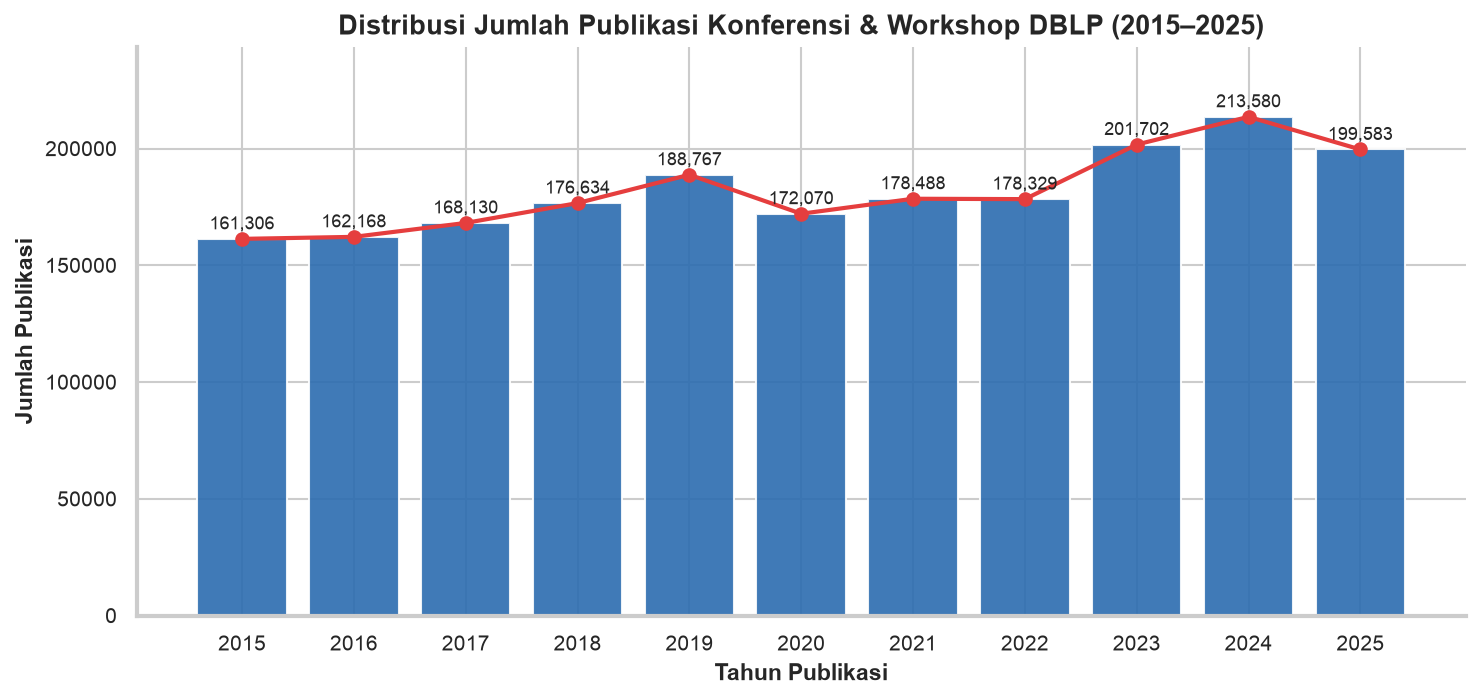

In [6]:
# Distribusi publikasi berdasarkan tahun (2015-2025)
year_counts = df_clean["year"].value_counts().sort_index()
year_df = year_counts.reset_index()
year_df.columns = ["year", "publications"]
year_df.to_csv("../tables/publications_per_year.csv", index=False)
display(year_df)

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.bar(year_df["year"].astype(str), year_df["publications"], color="#2b6cb0", alpha=0.9)
ax.plot(year_df["year"].astype(str), year_df["publications"], color="#e53e3e", marker="o", linewidth=2)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 2500, f"{h:,}", ha="center", va="bottom", fontsize=8.5)
ax.set_title("Distribusi Jumlah Publikasi Konferensi & Workshop DBLP (2015–2025)", fontsize=13, fontweight="bold")
ax.set_xlabel("Tahun Publikasi")
ax.set_ylabel("Jumlah Publikasi")
ax.set_ylim(0, year_df["publications"].max() * 1.14)
plt.tight_layout()
plt.savefig("../outputs/figures/01_publications_per_year.png", dpi=150)
plt.show()


Statistik deskriptif jumlah publikasi per venue:


,publications_per_venue
count,8780.000000
mean,227.876651
std,847.021790
min,1.000000
25%,16.000000
50%,48.500000
75%,180.000000
max,25004.000000


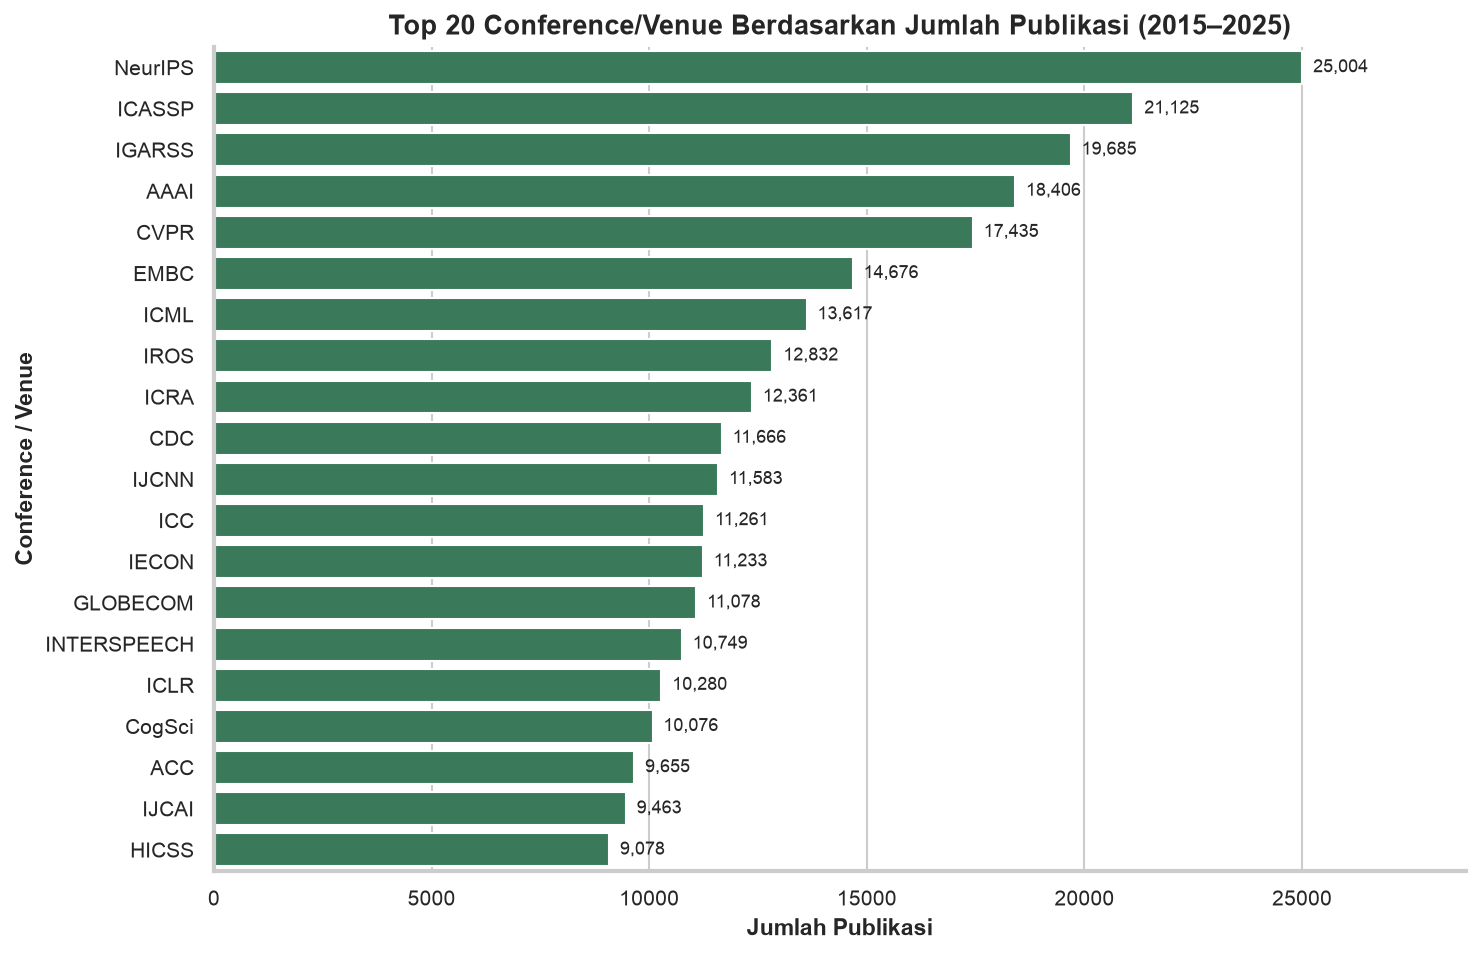

In [7]:
# Distribusi publikasi berdasarkan conference/venue
venue_counts = df_clean["venue"].value_counts()
print("Statistik deskriptif jumlah publikasi per venue:")
display(venue_counts.describe().to_frame("publications_per_venue"))

top20_venues = venue_counts.head(20).reset_index()
top20_venues.columns = ["venue", "publications"]
top20_venues.to_csv("../tables/top20_venues.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.barplot(data=top20_venues, y="venue", x="publications", color="#2f855a", ax=ax)
for i, row in top20_venues.iterrows():
    ax.text(row["publications"] + 250, i, f"{row['publications']:,}", va="center", fontsize=8.5)
ax.set_title("Top 20 Conference/Venue Berdasarkan Jumlah Publikasi (2015–2025)", fontsize=13, fontweight="bold")
ax.set_xlabel("Jumlah Publikasi")
ax.set_ylabel("Conference / Venue")
ax.set_xlim(0, top20_venues["publications"].max() * 1.15)
plt.tight_layout()
plt.savefig("../outputs/figures/01_top20_venues.png", dpi=150)
plt.show()


## 2. Task 2 — Conference Popularity Analysis

Analisis berikut mengukur popularitas konferensi berdasarkan dua metrik utama:
1. **Jumlah publikasi** (`publications`)
2. **Jumlah author unik** (`unique_authors`)

In [8]:
# 2.1 Top 10 konferensi berdasarkan jumlah publikasi
top10_pub = venue_counts.head(10).reset_index()
top10_pub.columns = ["venue", "publications"]
top10_pub["rank_pub"] = np.arange(1, len(top10_pub) + 1)
top10_pub = top10_pub[["rank_pub", "venue", "publications"]]
top10_pub.to_csv("../tables/top10_conferences_by_publications.csv", index=False)
print("Top 10 Konferensi Berdasarkan Jumlah Publikasi:")
display(top10_pub)

# 2.2 Top 10 konferensi berdasarkan jumlah author unik
df_exploded = df_clean[["venue", "authors"]].explode("authors")
venue_unique_authors = df_exploded.groupby("venue")["authors"].nunique().sort_values(ascending=False)

top10_auth = venue_unique_authors.head(10).reset_index()
top10_auth.columns = ["venue", "unique_authors"]
top10_auth["rank_auth"] = np.arange(1, len(top10_auth) + 1)
top10_auth = top10_auth[["rank_auth", "venue", "unique_authors"]]
top10_auth.to_csv("../tables/top10_conferences_by_unique_authors.csv", index=False)
print("Top 10 Konferensi Berdasarkan Jumlah Author Unik:")
display(top10_auth)


Top 10 Konferensi Berdasarkan Jumlah Publikasi:


,rank_pub,venue,publications
0,1,NeurIPS,25004
1,2,ICASSP,21125
2,3,IGARSS,19685
3,4,AAAI,18406
4,5,CVPR,17435
5,6,EMBC,14676
6,7,ICML,13617
7,8,IROS,12832
8,9,ICRA,12361
9,10,CDC,11666


Top 10 Konferensi Berdasarkan Jumlah Author Unik:


,rank_auth,venue,unique_authors
0,1,NeurIPS,56073
1,2,AAAI,44604
2,3,ICASSP,41097
3,4,EMBC,39318
4,5,IGARSS,35229
5,6,CVPR,34970
6,7,ICML,31397
7,8,IROS,31200
8,9,IJCNN,29803
9,10,ICLR,28751


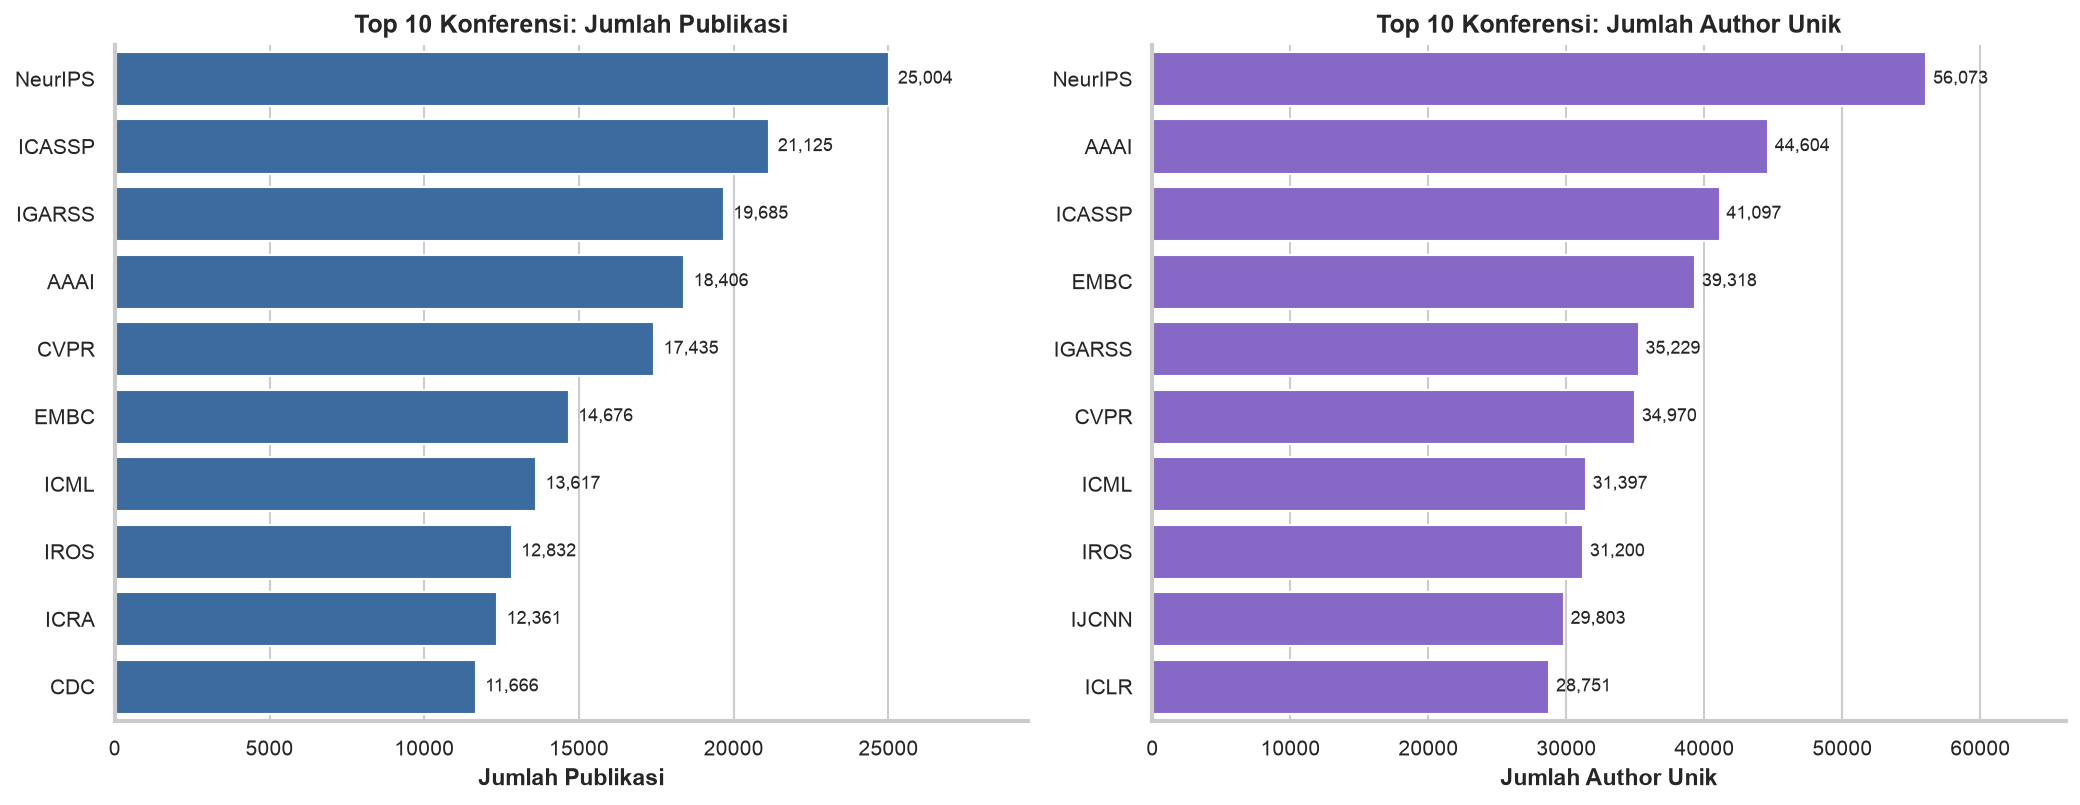

In [9]:
# Visualisasi Top 10 Publikasi vs Top 10 Author Unik
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.barplot(data=top10_pub, y="venue", x="publications", color="#2b6cb0", ax=axes[0])
axes[0].set_title("Top 10 Konferensi: Jumlah Publikasi", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Jumlah Publikasi")
axes[0].set_ylabel("")
axes[0].set_xlim(0, top10_pub["publications"].max() * 1.18)
for i, row in top10_pub.iterrows():
    axes[0].text(row["publications"] + 300, i, f"{row['publications']:,}", va="center", fontsize=8.5)

sns.barplot(data=top10_auth, y="venue", x="unique_authors", color="#805ad5", ax=axes[1])
axes[1].set_title("Top 10 Konferensi: Jumlah Author Unik", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Jumlah Author Unik")
axes[1].set_ylabel("")
axes[1].set_xlim(0, top10_auth["unique_authors"].max() * 1.18)
for i, row in top10_auth.iterrows():
    axes[1].text(row["unique_authors"] + 500, i, f"{row['unique_authors']:,}", va="center", fontsize=8.5)

plt.tight_layout()
plt.savefig("../outputs/figures/02_top10_pub_vs_unique_authors.png", dpi=150)
plt.show()


venue,NeurIPS,ICASSP,IGARSS,AAAI,CVPR,EMBC,ICML,IROS,ICRA,CDC
year,,,,,,,,,,
2015,403,1198,1353,673,601,2004,270,970,940,1258
2016,566,1322,1905,691,643,1578,322,830,693,1213
2017,677,1321,1569,785,783,1123,434,878,795,1023
2018,1009,1395,2208,1100,979,1473,621,1086,816,1054
2019,1426,1735,2273,1340,1294,1669,773,934,1024,1195
2020,1898,1863,1641,1864,1465,1462,1085,1128,1073,768
2021,2334,1723,2152,1960,1660,1639,1183,1032,1386,935
2022,2834,1864,1936,1623,2071,1105,1234,1213,929,980
2023,3540,2720,2059,2020,2353,1237,1828,1195,1341,1119


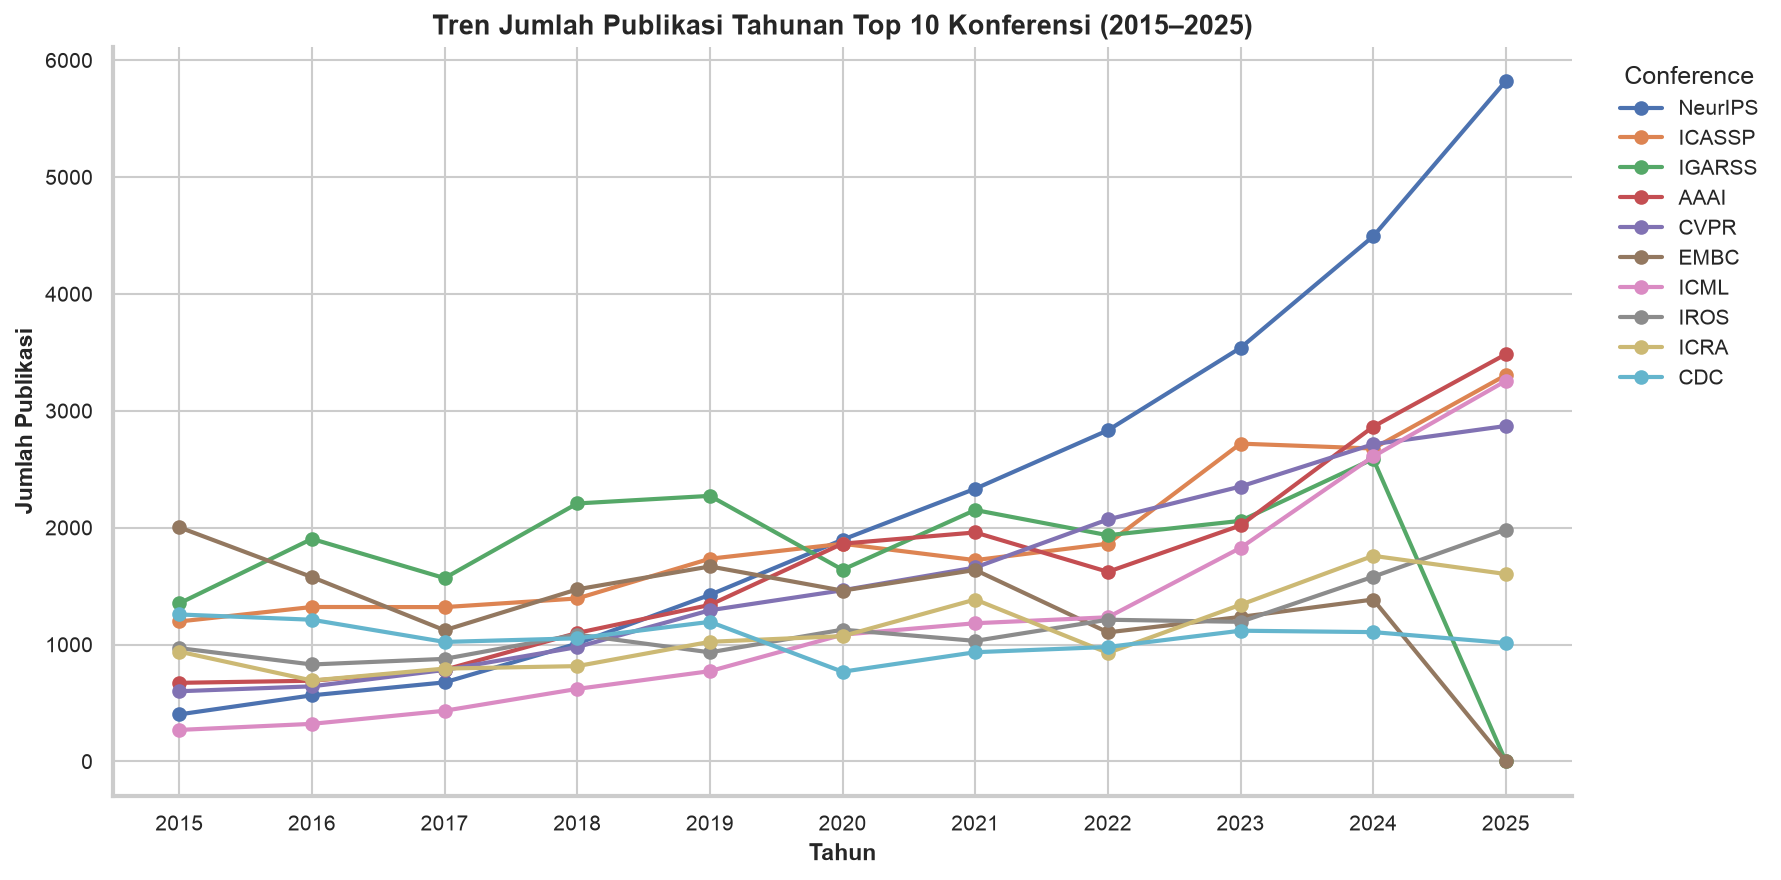

In [10]:
# 2.3 Tren jumlah publikasi Top 10 konferensi per tahun (2015-2025)
top10_names = top10_pub["venue"].tolist()
trend_df = (
    df_clean[df_clean["venue"].isin(top10_names)]
    .groupby(["year", "venue"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=top10_names)
)
trend_df.to_csv("../tables/top10_conferences_yearly_trend.csv")
display(trend_df)

fig, ax = plt.subplots(figsize=(12, 6))
for col in trend_df.columns:
    ax.plot(trend_df.index, trend_df[col], marker="o", linewidth=2, label=col)
ax.set_title("Tren Jumlah Publikasi Tahunan Top 10 Konferensi (2015–2025)", fontsize=13, fontweight="bold")
ax.set_xlabel("Tahun")
ax.set_ylabel("Jumlah Publikasi")
ax.set_xticks(trend_df.index)
ax.legend(title="Conference", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("../outputs/figures/02_top10_conferences_trend.png", dpi=150)
plt.show()


,venue,publications,unique_authors,rank_pub,rank_auth,rank_diff,unique_authors_per_paper
0,NeurIPS,25004,56073,1,1,0,2.24
1,ICASSP,21125,41097,2,3,-1,1.95
2,IGARSS,19685,35229,3,5,-2,1.79
3,AAAI,18406,44604,4,2,2,2.42
4,CVPR,17435,34970,5,6,-1,2.01
5,EMBC,14676,39318,6,4,2,2.68
6,ICML,13617,31397,7,7,0,2.31
7,IROS,12832,31200,8,8,0,2.43
8,ICRA,12361,28542,9,11,-2,2.31
9,CDC,11666,14393,10,35,-25,1.23


Korelasi Spearman (publications vs unique_authors, seluruh 8,780 venue): 0.9811


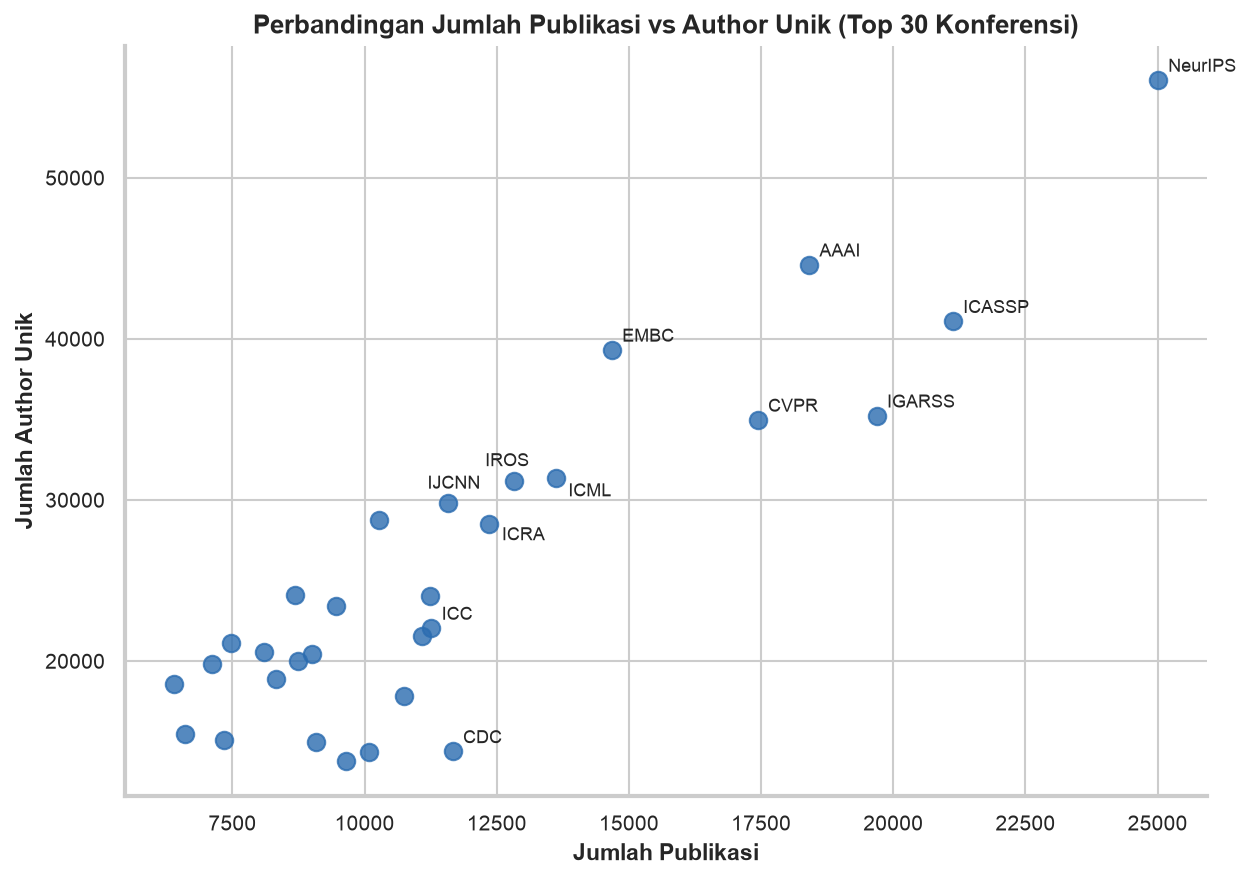

In [11]:
# 2.4 Perbandingan ranking publikasi vs jumlah author unik
all_stats = pd.DataFrame({
    "publications": venue_counts,
    "unique_authors": venue_unique_authors,
}).fillna(0)
all_stats["unique_authors"] = all_stats["unique_authors"].astype(int)
all_stats["rank_pub"] = all_stats["publications"].rank(ascending=False, method="min").astype(int)
all_stats["rank_auth"] = all_stats["unique_authors"].rank(ascending=False, method="min").astype(int)
all_stats["rank_diff"] = all_stats["rank_pub"] - all_stats["rank_auth"]
all_stats["unique_authors_per_paper"] = (all_stats["unique_authors"] / all_stats["publications"]).round(2)

top15_cmp = all_stats.sort_values("rank_pub").head(15).reset_index()
top15_cmp = top15_cmp.rename(columns={"index": "venue"})
top15_cmp.to_csv("../tables/ranking_comparison_pub_vs_authors.csv", index=False)
display(top15_cmp)

spearman_corr = all_stats["publications"].corr(all_stats["unique_authors"], method="spearman")
print(f"Korelasi Spearman (publications vs unique_authors, seluruh {len(all_stats):,} venue): {spearman_corr:.4f}")

fig, ax = plt.subplots(figsize=(8.5, 6))
top30_cmp = all_stats.sort_values("rank_pub").head(30).reset_index()
ax.scatter(top30_cmp["publications"], top30_cmp["unique_authors"], s=70, color="#2b6cb0", alpha=0.8)
offsets = {"IROS": (-14, 7), "ICML": (6, -9), "ICRA": (6, -8), "IJCNN": (-10, 7)}
for _, row in top30_cmp.head(12).iterrows():
    dx, dy = offsets.get(row["venue"], (5, 4))
    ax.annotate(row["venue"], (row["publications"], row["unique_authors"]),
                xytext=(dx, dy), textcoords="offset points", fontsize=8.5)
ax.set_title("Perbandingan Jumlah Publikasi vs Author Unik (Top 30 Konferensi)", fontsize=12.5, fontweight="bold")
ax.set_xlabel("Jumlah Publikasi")
ax.set_ylabel("Jumlah Author Unik")
plt.tight_layout()
plt.savefig("../outputs/figures/02_pub_vs_authors_scatter.png", dpi=150)
plt.show()


### 2.5 Interpretasi Hasil Analisis Popularitas (Task 2)

1. **Konferensi paling populer berdasarkan jumlah publikasi**:
   - **NeurIPS** menempati peringkat #1 dengan **25,004** publikasi (2015–2025), diikuti **ICASSP** (21,125), **IGARSS** (19,685), **AAAI** (18,406), dan **CVPR** (17,435).
2. **Apakah konferensi dengan publikasi terbanyak juga memiliki author unik terbanyak?**
   - **Ya, pada peringkat #1**: **NeurIPS** juga menempati peringkat #1 berdasarkan jumlah author unik (**56,073** author unik).
   - Namun pada peringkat di bawahnya terdapat perbedaan komposisi: **AAAI** naik dari peringkat #4 publikasi menjadi **#2** author unik (**44,604**), sedangkan **CDC** (#10 publikasi, 11,666 paper) turun ke peringkat **#35** author unik (14,393 author unik; rasio `1.23` author unik/paper) karena komunitasnya lebih terkonsentrasi pada penulis yang berulang. Sebaliknya, **IJCNN** (#9, 29,803) dan **ICLR** (#10, 28,751) masuk ke Top 10 author unik.
3. **Tren aktivitas publikasi konferensi (2015–2025)**:
   - Total publikasi meningkat dari **161,306** (2015) hingga puncaknya **213,580** (2024), dengan penurunan sementara pada 2020 (**172,070**, dampak pandemi COVID-19) dan 2025 (**199,583**, salah satunya karena keterlambatan indeksasi sebagian prosiding IEEE seperti `IGARSS` dan `EMBC` yang masih tercatat `0` pada dump 2025).
   - Konferensi AI/ML mengalami pertumbuhan paling eksplosif selama 2015–2025: **NeurIPS** (`403` -> `5,823`, ~14.4x), **ICML** (`270` -> `3,257`, ~12.1x), **AAAI** (`673` -> `3,485`, ~5.2x), dan **CVPR** (`601` -> `2,871`, ~4.8x).
